<!-- @format -->

# Garbage Classification

## 2. Data Preparation

Phần này chuẩn bị dữ liệu cho bước huấn luyện, dựa trên các phát hiện ở EDA: loại ảnh trùng, mã hóa nhãn, chia development và final test, xử lý mất cân bằng lớp và xây dựng pipeline đọc ảnh.

### 2.1. Load dataset

Dataset bản `enhanced` được đọc từ thư mục đã tải ở notebook EDA (`../data/raw`).

In [1]:
# [Prep 2.1] Import module và load dataset
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import modules.eda as eda
import modules.data_prep as prep

SEED = 42
img_dirs, csv_files = eda.find_dataset("../data/raw")
ENHANCED_KEY = next(k for k in img_dirs if "enhanced" in k.lower())
df = eda.build_image_df(img_dirs[ENHANCED_KEY])

Thư mục ảnh:
  - garbage_classification_corrected: ../data/raw/garbage_classification_corrected
  - garbage_classification_enhanced: ../data/raw/garbage_classification_enhanced
File CSV:
  - ../data/raw/labels_corrections.csv
Dataset shape: (15870, 4)
Số lớp  : 12
Các lớp : ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

File extension:
ext
.jpg    15870
Name: count, dtype: int64


<!-- @format -->

### 2.2. Remove duplicates

Theo EDA, có `4` ảnh nằm trong các nhóm trùng, tạo thành `2` nhóm và cả hai nhóm đều gồm các ảnh giống hệt nhau nhưng khác nhãn. Phần này loại bỏ ảnh trùng **trước khi chia dữ liệu**, để cùng một ảnh không xuất hiện đồng thời ở tập học và tập kiểm tra. Các bản trùng cùng nhãn chỉ giữ một bản, còn các nhóm trùng khác nhãn bị loại cả nhóm vì không xác định được nhãn đúng.

Các ảnh `RGBA` và `P` không bị loại mà được chuyển về `RGB` ở bước đọc ảnh (mục 2.8).

In [2]:
# [Prep 2.2] Loại ảnh trùng (kể cả trùng khác nhãn)
df = prep.remove_duplicates(df)

Nhóm ảnh trùng: 2 | trong đó khác nhãn: 2
Giữ 15866 ảnh; bỏ 4 ảnh.


<!-- @format -->

### 2.3. Label encoding

Mô hình cần nhãn dạng số, nên mỗi lớp được gán một chỉ số từ `0` đến `11` theo thứ tự bảng chữ cái. Ánh xạ này sẽ được lưu lại để các notebook sau dùng chung.

In [3]:
# [Prep 2.3] Mã hóa nhãn
classes = sorted(df["label"].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}
print(label2id)

{'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}


<!-- @format -->

### 2.4. Development / final test split

Nếu vừa nhìn kết quả trên một tập vừa liên tục sửa mô hình để đạt điểm cao hơn trên chính tập đó, điểm số sẽ không còn là một phép kiểm tra độc lập. Vì vậy dữ liệu được chia thành:

- **Development (80%)**: nơi huấn luyện, chọn mô hình và chỉnh siêu tham số. Phần này được chia tiếp thành **train** (học) và **val** (đánh giá trong lúc huấn luyện, tỷ lệ `20%` development).
- **Final test (20%)**: cất riêng, chỉ dùng một lần ở cuối để chấm mô hình đã chọn.

Việc chia dùng `stratify` theo lớp để mỗi tập giữ tỷ lệ các lớp gần như dataset gốc, quan trọng vì `clothes` chiếm `33%` còn `brown-glass` chỉ `3.9%`.

In [4]:
# [Prep 2.4] Chia development (train + val) và final test
train, val, test = prep.split_dataset(df, test_size=0.2, val_size=0.2, seed=SEED)

Development: 12692 (train 10153 + val 2539) | Final test: 3174


<!-- @format -->

### 2.5. Split verification

Phần này kiểm tra lại việc chia: phân phối các lớp ở ba tập có gần nhau không, có ảnh nào xuất hiện ở hai tập cùng lúc không, và các kích thước ảnh phổ biến có phân bố tương tự giữa các tập không. Kiểm tra kích thước là cần thiết vì EDA cho thấy kích thước ảnh liên hệ chặt với lớp, nên nếu một nhóm kích thước lệch hẳn sang một tập thì điểm đánh giá có thể bị sai lệch.

In [5]:
# [Prep 2.5] Kiểm tra phân phối lớp, rò rỉ ảnh trùng và phân bố kích thước
prep.check_split(train, val, test)

=== Phân phối lớp (%) ===
             train    val   test
label                           
clothes      33.31  33.32  33.33
shoes        12.65  12.64  12.63
paper         6.98   6.97   6.99
biological    6.52   6.54   6.52
battery       6.17   6.18   6.18
cardboard     5.90   5.91   5.89
plastic       5.67   5.67   5.67
metal         5.27   5.28   5.26
white-glass   5.00   5.00   5.01
trash         4.58   4.57   4.57
green-glass   4.05   4.02   4.03
brown-glass   3.90   3.90   3.91

Không có ảnh trùng giữa các tập.

=== Top 5 kích thước phổ biến nhất (%) ===
         train    val   test
size                        
400x533  16.22  16.31  16.73
512x384  14.80  14.42  15.22
225x225  12.64  12.84  12.07
400x534   6.70   7.33   6.68
275x183   4.16   4.37   4.79


<!-- @format -->

### 2.6. Class imbalance

Dataset mất cân bằng (tỷ lệ lớp lớn nhất/nhỏ nhất là `8.54`), nên các lớp ít ảnh dễ bị mô hình bỏ qua. Phần này tính **class weight** theo nghịch đảo tần suất, để khi dùng làm trọng số của hàm loss, sai sót ở lớp ít ảnh bị phạt nặng hơn. Trọng số chỉ được tính từ **tập train**, không dùng val hay test để tránh rò rỉ thông tin.

In [6]:
# [Prep 2.6] Class weight tính từ tập train
class_weights = prep.compute_class_weights(train, label2id)

             count  weight
label                     
battery        626   1.352
biological     662   1.278
brown-glass    396   2.137
cardboard      599   1.412
clothes       3382   0.250
green-glass    411   2.059
metal          535   1.581
paper          709   1.193
plastic        576   1.469
shoes         1284   0.659
trash          465   1.820
white-glass    508   1.666


<!-- @format -->

### 2.7. Transforms and normalization

Các lựa chọn xử lý ảnh dựa trên EDA:

- **Không kéo giãn hoặc pad ảnh.** Kích thước ảnh gắn chặt với lớp, nên tập train dùng `RandomResizedCrop` (tỷ lệ ngẫu nhiên), còn val/test dùng resize cạnh ngắn rồi crop giữa về `224x224`.
- **Chỉ đổi độ sáng và tương phản nhẹ.** Không đổi hue hay độ bão hòa vì ba lớp thủy tinh được phân biệt chủ yếu bằng màu.
- **Chỉ lật ngang và xoay nhẹ.**
- **Chuẩn hóa bằng mean/std của ImageNet** vì mô hình pretrained được huấn luyện với các giá trị này. Nếu huấn luyện từ đầu, thay bằng mean/std tính trên tập train.

Val và test không dùng augmentation để kết quả đánh giá ổn định.

In [7]:
# [Prep 2.7] Transform cho train (có augmentation) và cho val/test
IMG_SIZE = 224
train_tf, eval_tf = prep.get_transforms(img_size=IMG_SIZE)
print(train_tf)

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.5, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


<!-- @format -->

### 2.8. Dataset and DataLoader

Ảnh được đọc theo đường dẫn và luôn chuyển về `RGB`. Ảnh `RGBA` và `P` (có thể có nền trong suốt) được ghép lên nền trắng trước khi bỏ kênh alpha để vùng trong suốt không bị biến thành màu đen. Chỉ tập train được xáo trộn (`shuffle`); val và test giữ thứ tự cố định.

Để chắc pipeline hoạt động, ô code dưới in shape của một batch và hiển thị một số ảnh sau augmentation. Batch đúng sẽ có dạng `(32, 3, 224, 224)`.

{'train': '10153 ảnh, 318 batch', 'val': '2539 ảnh, 80 batch', 'test': '3174 ảnh, 100 batch'}
Batch images: (32, 3, 224, 224) | labels: (32,)


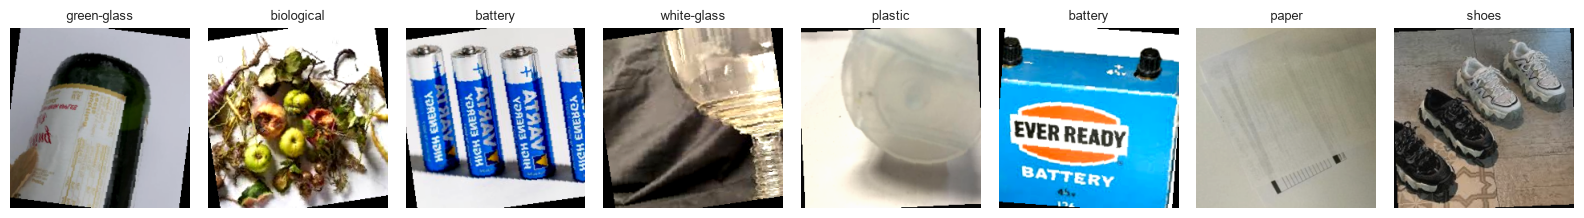

In [8]:
# [Prep 2.8] Tạo DataLoader và kiểm tra một batch
loaders = prep.make_loaders(train, val, test, label2id, train_tf, eval_tf, batch_size=32)
prep.show_batch(loaders["train"], id2label)

<!-- @format -->

### 2.9. Save prepared data

Kết quả được lưu ra `../data/processed/` để các notebook huấn luyện dùng lại mà không phải chia lại dữ liệu: danh sách ảnh kèm cột `split` (`train`/`val`/`test`), ánh xạ nhãn, class weight và cấu hình đã dùng.

In [9]:
# [Prep 2.9] Lưu dữ liệu đã chuẩn bị cho các notebook huấn luyện
config = {
    "seed": SEED, "img_size": IMG_SIZE,
    "mean": list(prep.IMAGENET_MEAN), "std": list(prep.IMAGENET_STD),
    "test_size": 0.2, "val_size": 0.2,
}
prep.save_artifacts(train, val, test, label2id, class_weights, config, "../data/processed")

Đã lưu: ['class_weights.json', 'config.json', 'label2id.json', 'meta.csv']
